### Figure 5: Competition of threshold-topology heterogeneity

This notebook illustrates the scaling of the two regions of threshold and degree dominance, as well as the marginal regime. We plot the cascade parameter $\kappa$ against the mean degree $\langle k \rangle = z$ with our leading analytical asymptotes and prefactors. 

We also plot the effective slope, the derivative $\frac{d\ln \kappa}{d\ln z}$ with respect to the mean degree. This illustrates the scaling, as well as the marginal logarithmic correction.

In [1]:
# Import statements
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.special import betaln, betainc, gammaln, zeta as hurwitz_zeta
from scipy.stats import beta as beta_dist, betabinom
from figstyle import save

# Choice of parameters to test limits. n.b., these are arbitrary; they should hold for any value. See sympy_asymptotics for symbolic verification.
alpha_d, beta_d = 0.75, 3.0
beta_th, phi_bar = 3.0, 0.20
m_d = alpha_d / (alpha_d + beta_d)

# Boundary between threshold/degree dominated regimes: alpha_th = alpha_d + 2.
alpha_th_crit = alpha_d + 2.0

# Different threshold exponents to sweep across the two regimes.
alpha_th_values = np.array([1.50, 2.30, alpha_th_crit, 3.20, 4.00])

In [ ]:
# Geometric grid of mean degrees z = n*m_d, and the exact cascade parameter kappa.
n_values = np.unique(np.rint(np.geomspace(10, 20_000_000, 65)).astype(int)) # Returns this as an integer array, since np.geomspace is a float.
z_values = n_values * m_d

# Mean of the threshold distribution
m_th = alpha_th_values / (alpha_th_values + beta_th)

# Compute the exact BB/beta finite-n kappa over all k
kappa = np.empty((len(alpha_th_values), len(n_values)))
for j, n in enumerate(n_values):
    k = np.arange(2, n + 1, dtype=float)
    u = np.minimum(1.0, m_th[:, None] / (phi_bar * k)) # rescaled threshold distribution m/(k * phi)
    weight = k * (k - 1) * betabinom.pmf(k, n, alpha_d, beta_d) / (n * m_d) # k(k-1) p_k
    kappa[:, j] = beta_dist.cdf(u, alpha_th_values[:, None], beta_th) @ weight # find the sum on k of k(k-1) p_k F(1/k)

# the local logarithmic slope, dln(kappa)/dln(z)
slopes = np.array([np.gradient(np.log(row), np.log(z_values), edge_order=2) for row in kappa])

In [3]:
# Below are the functions to compute the four prefactors, Cth, C1, C2, and Cc.
def Cth(alpha_th):
    'Threshold prefactor C_th = m^alpha_th / [alpha_th B(alpha_th, beta_th) phi_bar^alpha_th], equation A6.'
    m = alpha_th / (alpha_th + beta_th)
    return np.exp(alpha_th * np.log(m) - np.log(alpha_th)
                  - betaln(alpha_th, beta_th) - alpha_th * np.log(phi_bar))

def C1(alpha_th):
    'Threshold-dominated prefactor C1, equation A27.'
    return Cth(alpha_th) * m_d ** (alpha_th - 2) * np.exp(betaln(alpha_d + 2 - alpha_th, beta_d) - betaln(alpha_d, beta_d))

def _degree_sum(alpha_th, cutoff=1_000_000):
    'Internal function for the sum in equation A31, sum_k k(k-1)Gamma(k+alpha_d)/k! F(1/k).'

    k = np.arange(2, cutoff + 1, dtype=float) # iterate k
    m = alpha_th / (alpha_th + beta_th) # find mean

    # Compute the CDF F(1/k) for the rescaled threshold
    f = beta_dist.cdf(np.minimum(1.0, m / (phi_bar * k)), alpha_th, beta_th)

    # This is summed exactly to the given cutoff in k, then closed with Hurwitz-zeta tail beyond it.
    return (k * (k - 1) * np.exp(gammaln(k + alpha_d) - gammaln(k + 1)) * f).sum() \
        + Cth(alpha_th) * hurwitz_zeta(alpha_th - alpha_d - 1, cutoff + 1)


def C2(alpha_th, cutoff=1_000_000):
    'Degree-dominated prefactor C2, equation A31.'
    return m_d ** alpha_d / np.exp(betaln(alpha_d, beta_d)) * _degree_sum(alpha_th, cutoff)

def Cc():
    'Marginal-case prefactor, equation A35.'
    return Cth(alpha_th_crit) * m_d ** alpha_d / np.exp(betaln(alpha_d, beta_d))


def asymptotic_kappa(z, alpha_th):
    'Build kappa to leading order based on the value of alpha_th, including marginal log correction.'

    if alpha_th < alpha_th_crit:
        return C1(alpha_th) * z ** (1 - alpha_th) # Eq. A26
    
    if np.isclose(alpha_th, alpha_th_crit):
        return Cc() * z ** (-(alpha_d + 1)) * np.log(z / m_d) # Eq. A34
    
    return C2(alpha_th) * z ** (-(alpha_d + 1)) # Eq. A30

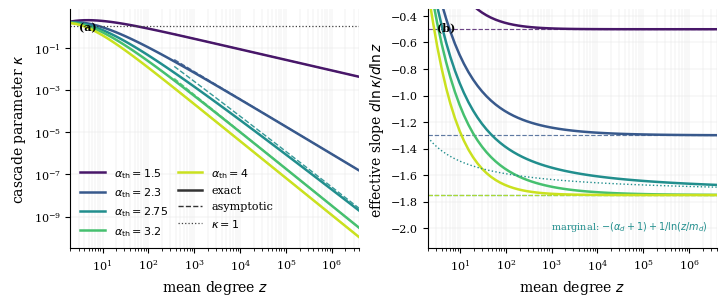

In [6]:
# Plot these two subplots below.

colors = plt.cm.viridis(np.linspace(0.06, 0.92, len(alpha_th_values))) # TODO, fix this to a better palatte?
fig, axes = plt.subplots(1, 2, figsize=(7.15, 2.95), constrained_layout=True)

# Plot the exact value of the kappa(z) along with its leading order asymptotic correction.
ax = axes[0]
for i, (alpha_th, color) in enumerate(zip(alpha_th_values, colors)):
    ax.loglog(z_values, kappa[i], color=color, lw=1.8)
    asymptote_region = z_values >= 300
    ax.loglog(z_values[asymptote_region], asymptotic_kappa(z_values[asymptote_region], alpha_th),
              color=color, lw=1.0, ls='--', alpha=0.9)
ax.axhline(1.0, color='0.25', lw=0.9, ls=':')
ax.set_xlabel(r'mean degree $z$')
ax.set_ylabel(r'cascade parameter $\kappa$')
ax.set_xlim(z_values[0], z_values[-1])
ax.text(0.03, 0.95, '(a)', transform=ax.transAxes, va='top', fontweight='bold')

color_handles = [
    Line2D([0], [0], color=color, lw=1.8, label=rf'$\alpha_{{\rm th}}={alpha_th:g}$')
    for alpha_th, color in zip(alpha_th_values, colors)
]
style_handles = [
    Line2D([0], [0], color='0.2', lw=1.8, ls='-', label='exact'),
    Line2D([0], [0], color='0.2', lw=1.0, ls='--', label='asymptotic'),
    Line2D([0], [0], color='0.25', lw=0.9, ls=':', label=r'$\kappa=1$'),
]
ax.legend(handles=color_handles + style_handles, frameon=False, ncol=2,
          loc='lower left', handlelength=2.2, columnspacing=0.9)
ax.grid(which='both', lw=0.35, color='0.9')

# Plot the slope and its limiting value per regime.
ax = axes[1]
for i, (alpha_th, color) in enumerate(zip(alpha_th_values, colors)):
    ax.semilogx(z_values, slopes[i], color=color, lw=1.8)
    limit = 1 - alpha_th if alpha_th < alpha_th_crit else -(alpha_d + 1)
    ax.axhline(limit, color=color, lw=0.85, ls='--', alpha=0.8)
marginal_guide = -(alpha_d + 1) + 1 / np.log(z_values / m_d)
ax.semilogx(z_values, marginal_guide, color=colors[2], lw=1.0, ls=':')
ax.set_xlabel(r'mean degree $z$')
ax.set_ylabel(r'effective slope $d\ln\kappa/d\ln z$')
ax.set_xlim(z_values[0], z_values[-1])
ax.set_ylim(-2.15, -0.35)
ax.text(0.03, 0.95, '(b)', transform=ax.transAxes, va='top', fontweight='bold')
ax.text(0.97, 0.06, r'marginal: $-(\alpha_d+1)+1/\ln(z/m_d)$', transform=ax.transAxes,
        ha='right', va='bottom', fontsize=7, color=colors[2])
ax.grid(which='both', lw=0.35, color='0.9')

save(fig, "figure5", bbox_inches='tight')
plt.show()

Below, we run some numerical checks.

In [ ]:
# We check that the C2 tail sum has converged.
for alpha_th in alpha_th_values[alpha_th_values > alpha_th_crit]:
    c_half, c_full = C2(alpha_th, 500_000), C2(alpha_th, 1_000_000)
    assert abs(c_full - c_half) / c_full < 2e-5, f"C2 tail not converged at alpha_th={alpha_th}"
    print(f"An alpha_th={alpha_th:g} gives a C2 relative difference (5e5 vs 1e6) of {abs(c_full - c_half) / c_full:.2e}")

# We check that the exact kappa lands on each asymptotic curve at the largest z.
for i, alpha_th in enumerate(alpha_th_values):
    if alpha_th == alpha_th_crit:
        continue
    ratio = kappa[i, -1] / asymptotic_kappa(z_values[-1], alpha_th)
    assert abs(ratio - 1) < 0.01, f"asymptote at alpha_th={alpha_th} off: ratio={ratio:.4f}"
    print(f"An alpha_th={alpha_th:g} gives kappa/asymptote to be {ratio:.4f}")

# We check the marginal case approaches logarithmic, so (1 - ratio) * ln(z/m_d) is constant.
i_c = np.where(alpha_th_values == alpha_th_crit)[0][0]
residuals = np.array([
    (1 - kappa[i_c, j] / asymptotic_kappa(z_values[j], alpha_th_crit)) * np.log(z_values[j] / m_d)
    for j in range(-5, 0)
])
assert np.ptp(residuals) / abs(residuals.mean()) < 1e-2, "marginal log correction not constant"
print(f"The marginal case yields (1-ratio)*ln(z/m_d) = {residuals.mean():.4f} with a spread {np.ptp(residuals):.1e}.")

# We check that the local slope approaches the predicted exponent at the largest z.
for i, alpha_th in enumerate(alpha_th_values):
    if alpha_th == alpha_th_crit:
        continue
    limit = 1 - alpha_th if alpha_th < alpha_th_crit else -(alpha_d + 1)
    assert abs(slopes[i, -1] - limit) < 0.01, f"slope at alpha_th={alpha_th} not approaching {limit}"
    print(f"An alpha_th={alpha_th:g} gives a slope at z_max of {slopes[i, -1]:+.4f} (limit {limit:+.4f})")

An alpha_th=3.2 gives a C2 relative difference (5e5 vs 1e6) of 1.38e-08
An alpha_th=4 gives a C2 relative difference (5e5 vs 1e6) of 4.21e-12
An alpha_th=1.5 gives kappa/asymptote to be 1.0000
An alpha_th=2.3 gives kappa/asymptote to be 0.9971
An alpha_th=3.2 gives kappa/asymptote to be 0.9969
An alpha_th=4 gives kappa/asymptote to be 1.0000
The marginal case yields (1-ratio)*ln(z/m_d) = 3.7418 with a spread 6.8e-06.
An alpha_th=1.5 gives a slope at z_max of -0.5000 (limit -0.5000)
An alpha_th=2.3 gives a slope at z_max of -1.2987 (limit -1.3000)
An alpha_th=3.2 gives a slope at z_max of -1.7486 (limit -1.7500)
An alpha_th=4 gives a slope at z_max of -1.7500 (limit -1.7500)
